# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nando135/flyrank_ml_1/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

Can unsupervised clustering identify meaningful content-performance archetypes from search visibility and engagement signals, and can those archetypes support a more useful content-review prioritization workflow than a manually defined rule-based baseline?
This study groups content pages using impressions, CTR, sessions, and engagement rate. The K-Means approach is compared with a rule-based baseline that ranks pages using manually weighted visibility, low CTR, and low engagement signals. The goal is not to predict a target label, but to identify recurring performance patterns and assess whether data-driven clusters provide clearer decision-support for human content review.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

The analysis uses the FlyRank ML Internship warehouse and focuses on March 2026. Daily content-performance records were filtered to rows where both Google Search Console and Google Analytics data were available, then aggregated to one row per client and content item.
The final page-level dataset contains 63,856 content items across 34 pseudonymized clients. The analysis uses impressions and clicks from search data, and sessions and engaged sessions from analytics data. CTR was calculated as clicks divided by impressions, while engagement rate was calculated as engaged sessions divided by sessions.
Rows without both GSC and GA4 availability were excluded so that search and engagement signals could be compared consistently. Client and content identifiers were retained only for grouping, validation, and traceability, not as model features. No client names, URLs, or private queries are included.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

## Features and Preprocessing

Two feature representations were used in this study: one for the rule-based baseline and one for the K-Means clustering model.

### Rule-Based Baseline

The baseline was designed as a review-priority score rather than a measure of content quality. It combined three signals: visibility, low CTR, and low engagement.

The visibility score was calculated using the percentile rank of impressions:

$$
VisibilityScore_i = PercentileRank(Impressions_i)
$$

CTR was calculated as:

$$
CTR_i = \frac{Clicks_i}{Impressions_i}
$$

Because lower CTR represented a stronger review signal, its percentile rank was inverted:

$$
LowCTRScore_i = 1 - PercentileRank(CTR_i)
$$

This transformation assigns a higher score to pages with relatively weaker CTR and a lower score to pages with relatively stronger CTR.

Engagement rate was calculated as:

$$
EngagementRate_i = \frac{EngagedSessions_i}{Sessions_i}
$$

The engagement percentile was also inverted:

$$
LowEngagementScore_i = 1 - PercentileRank(EngagementRate_i)
$$

The final baseline score was calculated as:

$$
BaselineScore_i =
0.40(VisibilityScore_i)
+
0.40(LowCTRScore_i)
+
0.20(LowEngagementScore_i)
$$

Visibility and low CTR each received a weight of 40%, while low engagement received 20%. This weighting reflected the earlier signal analysis, where visibility and CTR provided a stronger basis for identifying review opportunities, while engagement was retained as a supporting signal. A higher baseline score therefore represented a higher review priority.

### K-Means Model Features

The K-Means model used four page-level features: impressions, CTR, sessions, and engagement rate. CTR and engagement rate followed the same definitions used in the baseline.

Because impressions and sessions were strongly right-skewed, both were transformed using:

$$
x' = \log(1+x)
$$

This transformation reduced the influence of extreme traffic values while preserving the relative ordering of observations. CTR and engagement rate were retained in their original rate form.

All four features were then standardized using StandardScaler:

$$
z = \frac{x-\mu}{\sigma}
$$

where $\mu$ represents the training-set mean and $\sigma$ represents the training-set standard deviation.

The final clustering feature space was:

$$
[
LogImpressions,\ CTR,\ LogSessions,\ EngagementRate
]
$$

The scaler was fitted only on the training data and then applied to the validation data. Client and content identifiers were not used as model features.

K-Means begins by initializing a set of cluster centroids. Each observation is then assigned to the nearest centroid using Euclidean distance:

$$
d(x,\mu_j)
=
\left(
\sum_{m=1}^{p}
(x_m-\mu_{jm})^2
\right)^{1/2}
$$

where $x$ represents an observation, $\mu_j$ represents the centroid of cluster $j$, and $p$ represents the number of features.

After observations are assigned to clusters, each centroid is recalculated using the mean of all observations belonging to that cluster:

$$
\mu_j =
\frac{1}{|C_j|}
\sum_{x_i \in C_j} x_i
$$

The assignment and centroid update process is repeated until the cluster assignments stabilize or the centroids no longer change substantially.

Cluster quality was evaluated using the silhouette score:

$$
s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}
$$

Higher silhouette values indicate stronger cohesion within clusters and greater separation between clusters, while values near zero indicate greater overlap. The silhouette score was used to compare different cluster configurations and select the final number of clusters.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

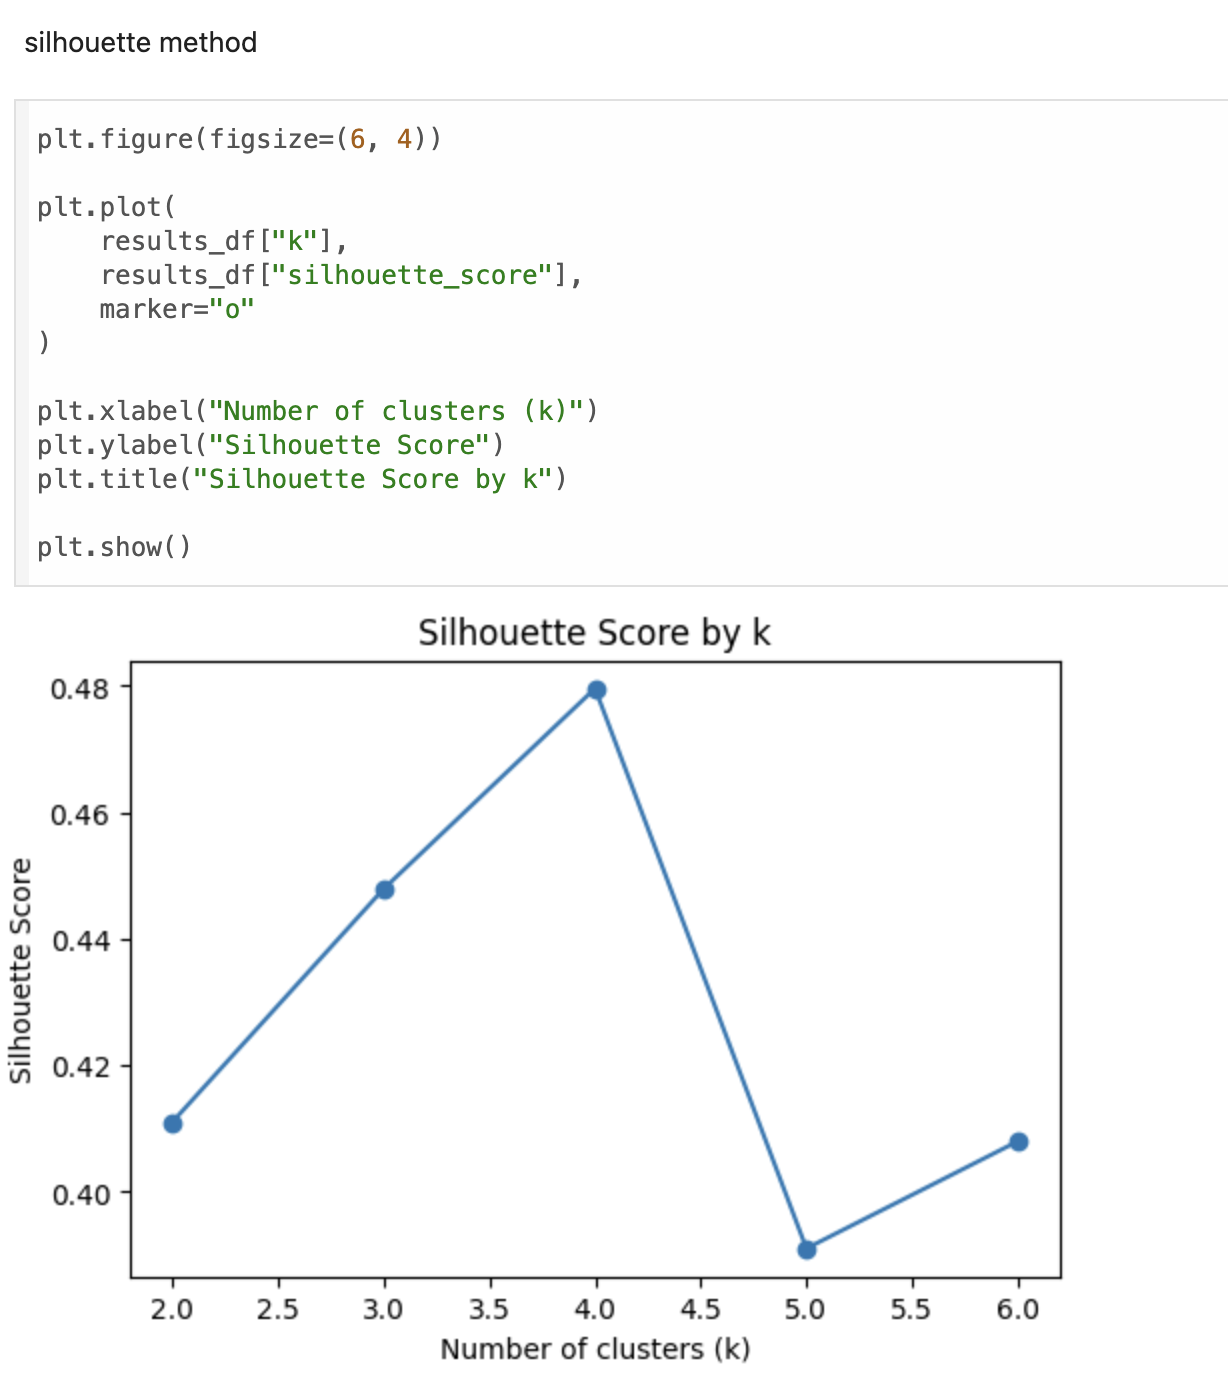




The silhouette analysis showed that \(k=4\) produced the strongest cluster separation among the tested configurations, with a training silhouette score of approximately 0.480. This suggests that four clusters provided the best balance between within-cluster cohesion and separation from other clusters.

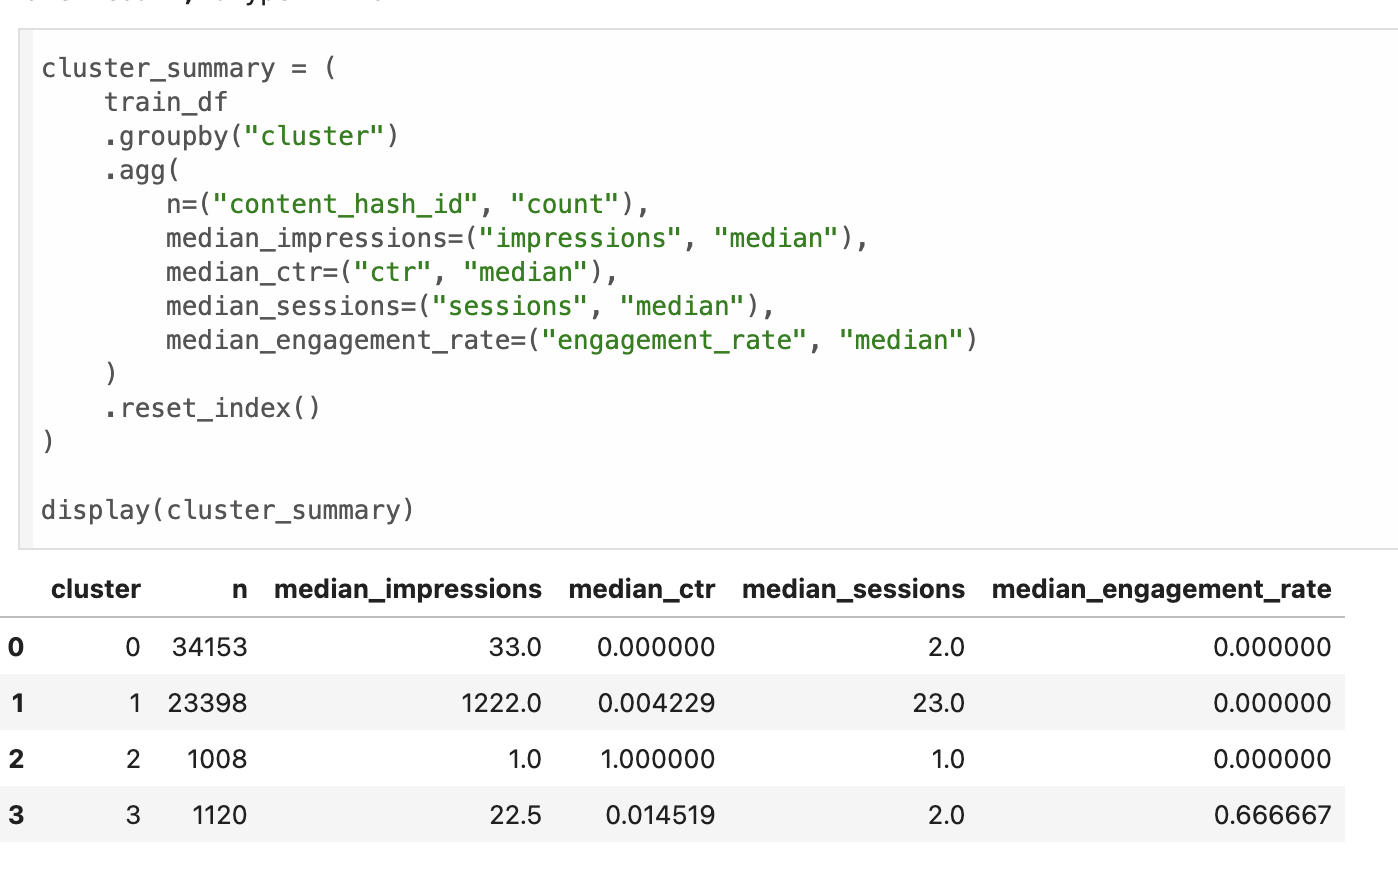

The four clusters exhibited distinct performance characteristics. Cluster 0 contained the largest number of pages and was characterized by low impressions, zero median CTR, low sessions, and zero median engagement. Cluster 1 represented higher-visibility pages, with substantially greater median impressions and sessions but still relatively weak CTR and engagement. Cluster 2 consisted of very low-volume pages with a median CTR of 1.0, indicating that extreme rates may be driven by small denominators. Cluster 3 contained lower-volume pages but showed the strongest median engagement rate among the four clusters.
These patterns were interpreted as descriptive performance archetypes rather than fixed measures of content quality.

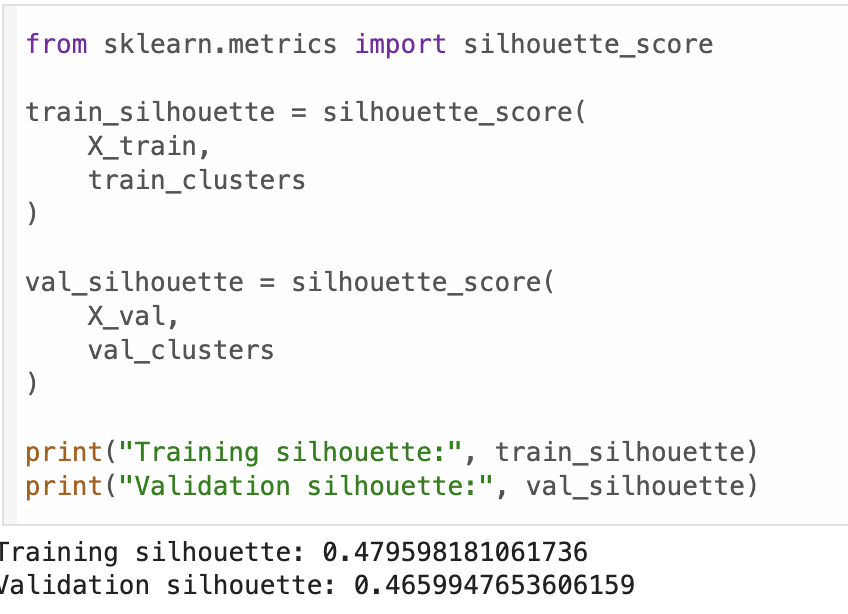

The final K-Means model achieved a training silhouette score of approximately 0.480 and a validation silhouette score of approximately 0.466. The relatively small reduction in validation performance suggests that the cluster structure remained reasonably stable when applied to unseen clients, rather than being limited only to the training data.

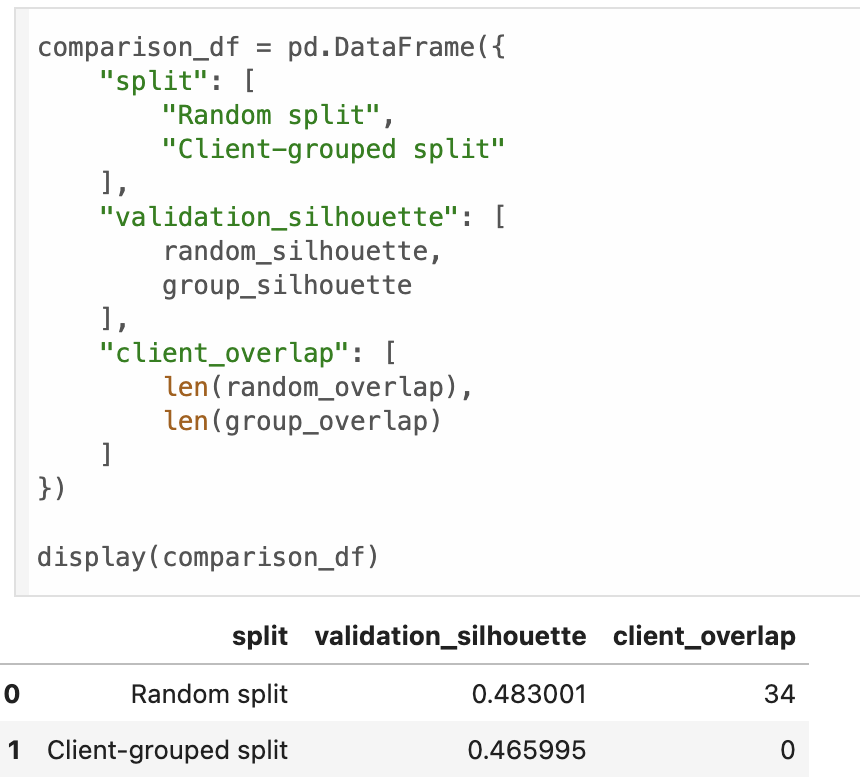

The random split achieved a validation silhouette score of 0.483, while the client-grouped split achieved 0.466. Although the random split produced a slightly higher score, it had an overlap of 34 clients between the training and validation sets. In contrast, the client-grouped split had zero client overlap, making it a stricter evaluation of performance on unseen clients. Therefore, the client-grouped result was used as the more conservative validation estimate.

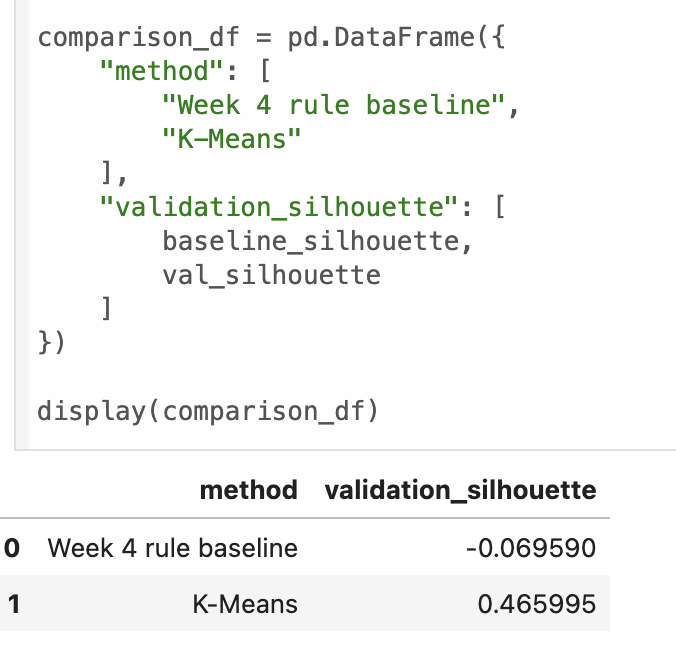

The rule-based baseline produced a validation silhouette score of -0.070, while K-Means achieved 0.466. This indicates that the K-Means solution formed substantially more coherent groups in the feature space. However, the comparison should be interpreted cautiously because the baseline was originally designed as a review-priority score rather than a clustering method, and was converted into groups only for comparison.

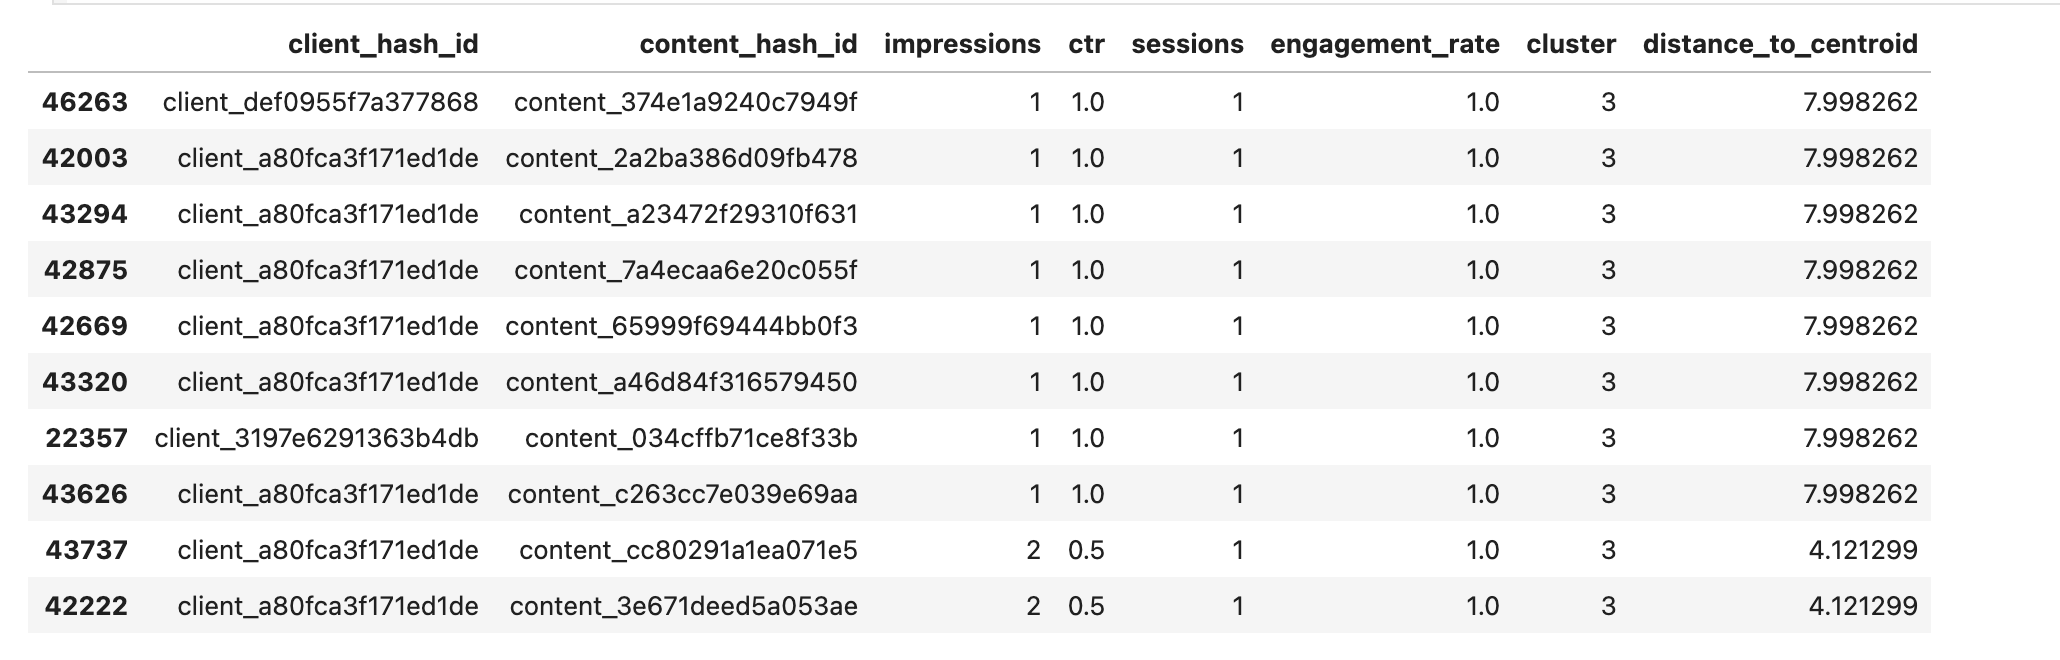

The most distant validation observations were concentrated in Cluster 3 and were primarily very low-volume pages with extreme rate values. Several observations had only one impression and one session while recording a CTR and engagement rate of 1.0. Because these ratios were calculated from very small denominators, they can appear extreme despite being supported by very little activity.
This suggests that low-volume pages may produce unstable rate-based features and become unusually distant from their assigned centroid. A future improvement would be to introduce minimum-volume thresholds or smoothed rate estimates before clustering.

## 5. Limitations

*What this work cannot claim.*

This study is limited to data from March 2026, so the identified clusters may not represent longer term or seasonal behavior. The model also uses only four features: impressions, CTR, sessions, and engagement rate, while other factors such as content type, topic, and search intent were not included.
Rate based features can also be unstable for very low volume pages, as shown in the error analysis. In addition, the client grouped validation tests generalization to unseen clients but does not evaluate future time periods.
The clusters are descriptive rather than causal. Their purpose is to help users identify which groups of content should be prioritized for review based on their performance patterns, rather than to make automatic content decisions.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

The cluster profiles were converted into a ranked action playbook to support human content review.
1. Cluster 1 should receive the highest priority because it contains pages with relatively high visibility but weak response. The recommended action is to review the content and search snippet.
2. Cluster 0 should receive the second priority. These pages have low visibility and weak response, so they should be reviewed when they are strategically important.
3. Cluster 3 should be monitored and protected because these pages show comparatively strong engagement despite lower traffic volume.
4. Cluster 2 should receive the lowest immediate action priority because its extreme rates are often based on very small volumes. More data should be collected before making decisions.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

The following figures and tables summarize the main artifacts used in the final deployed paper.

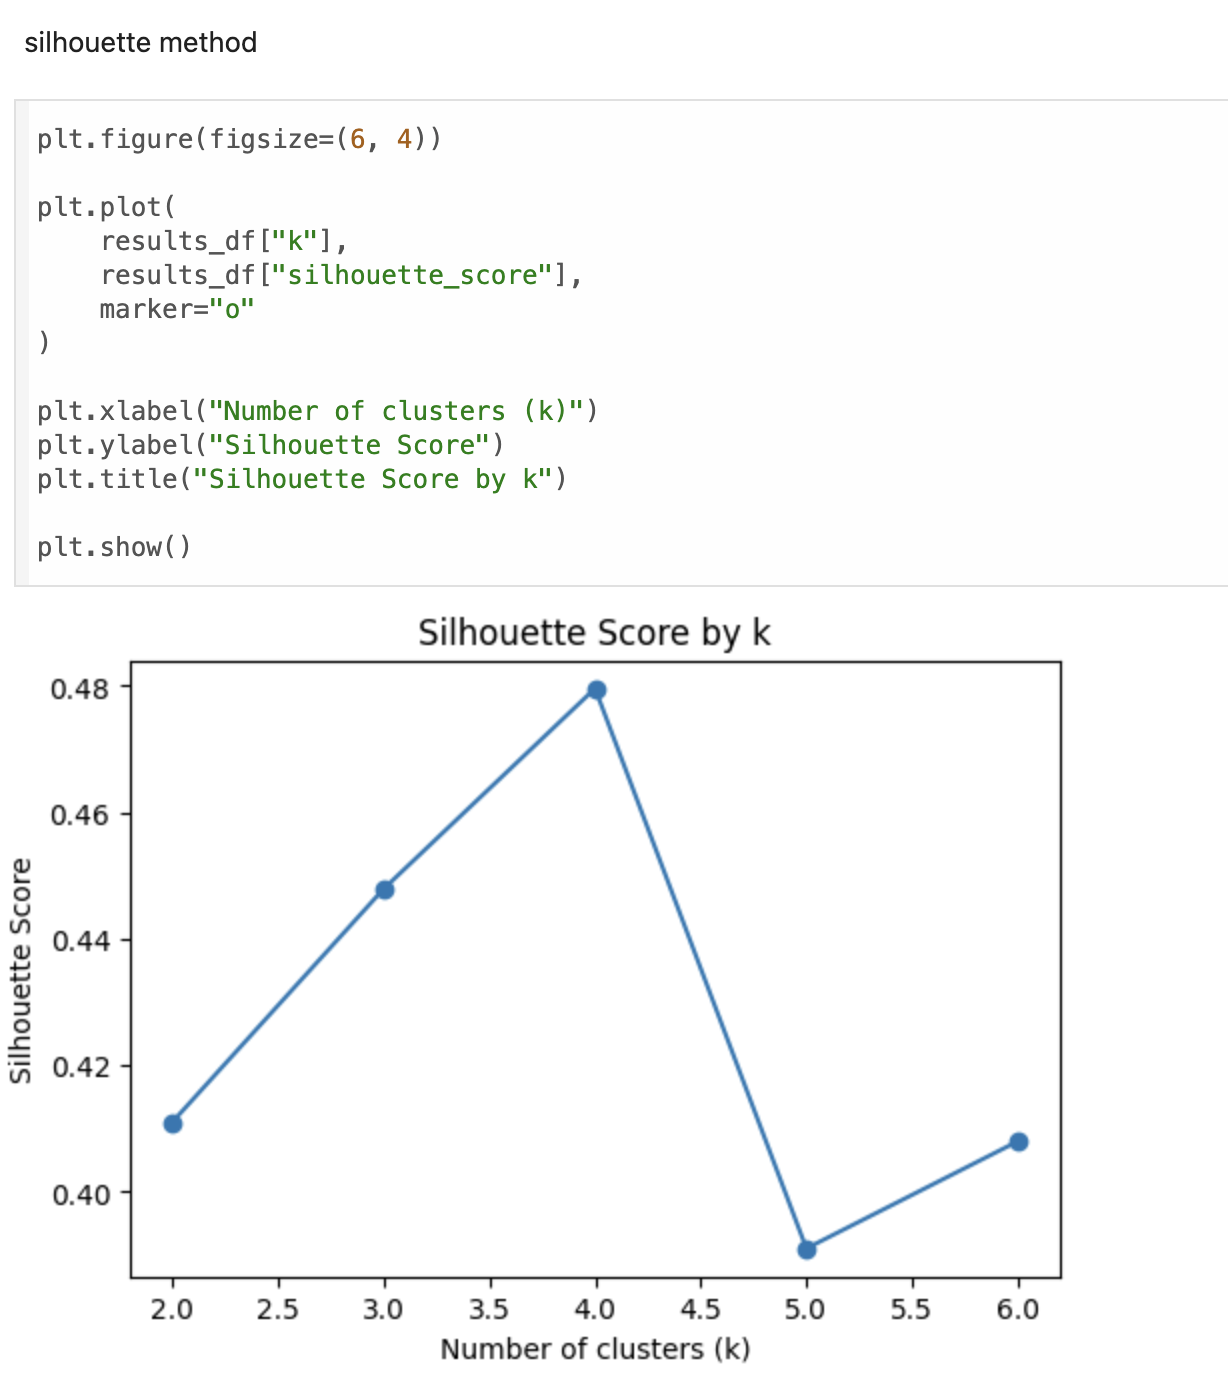




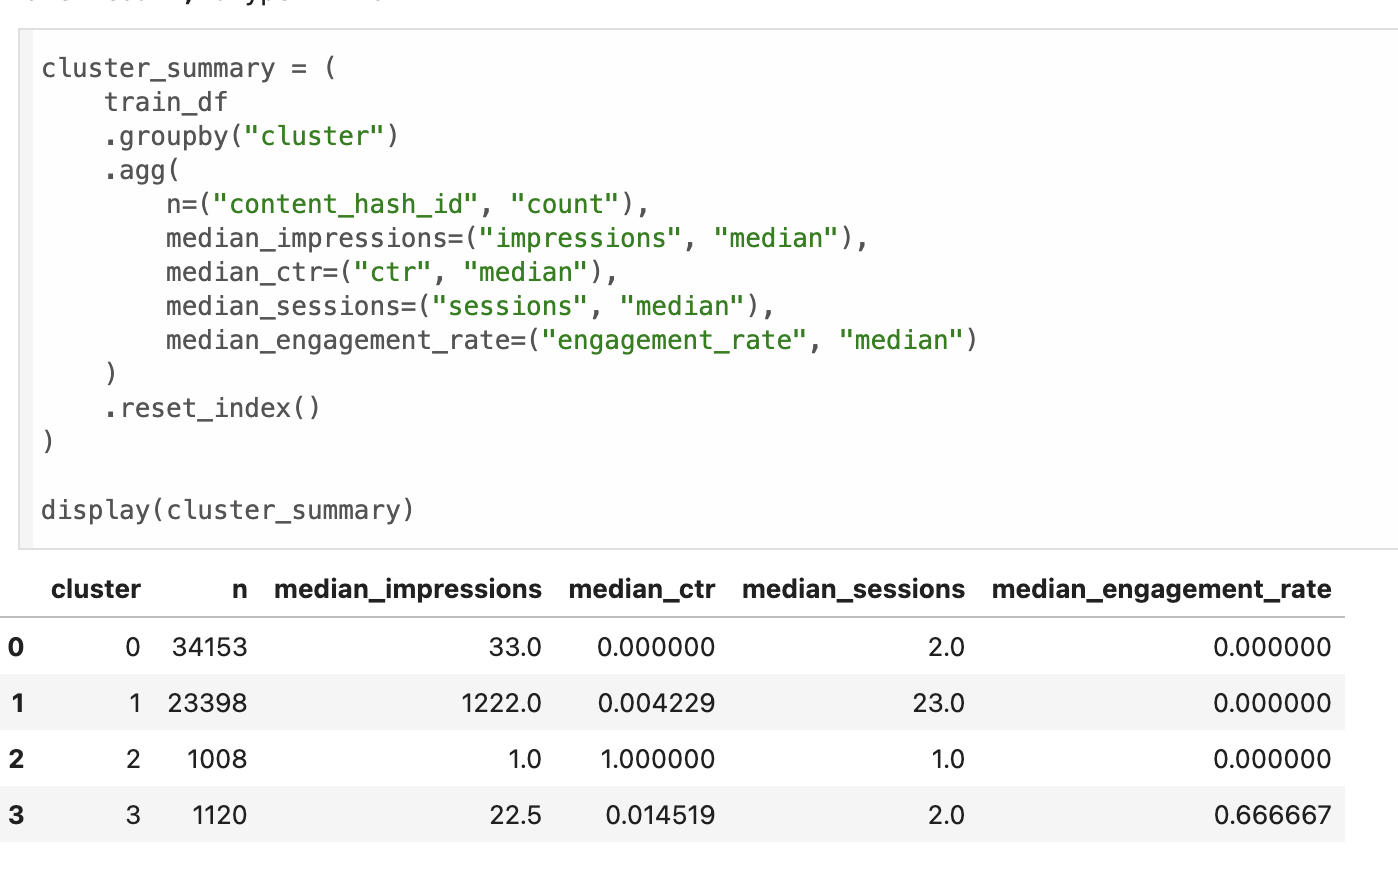

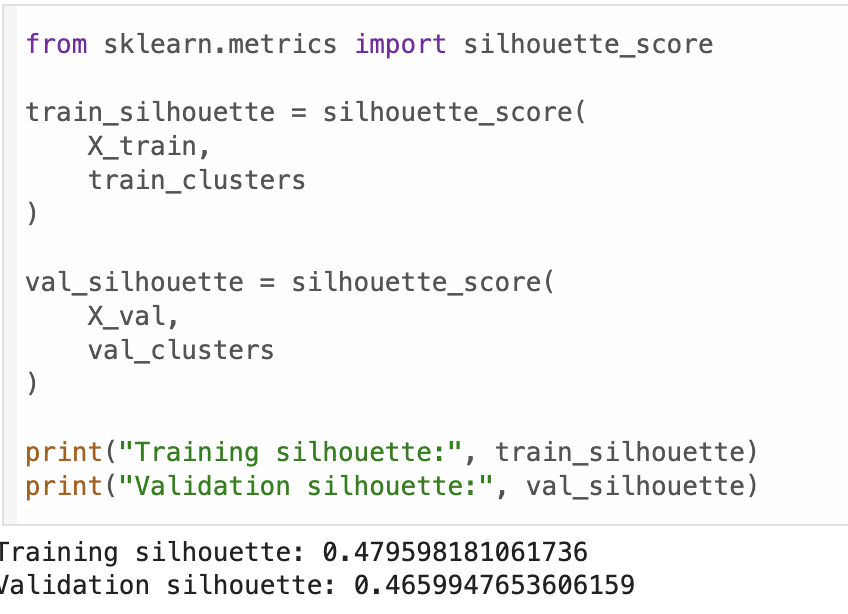

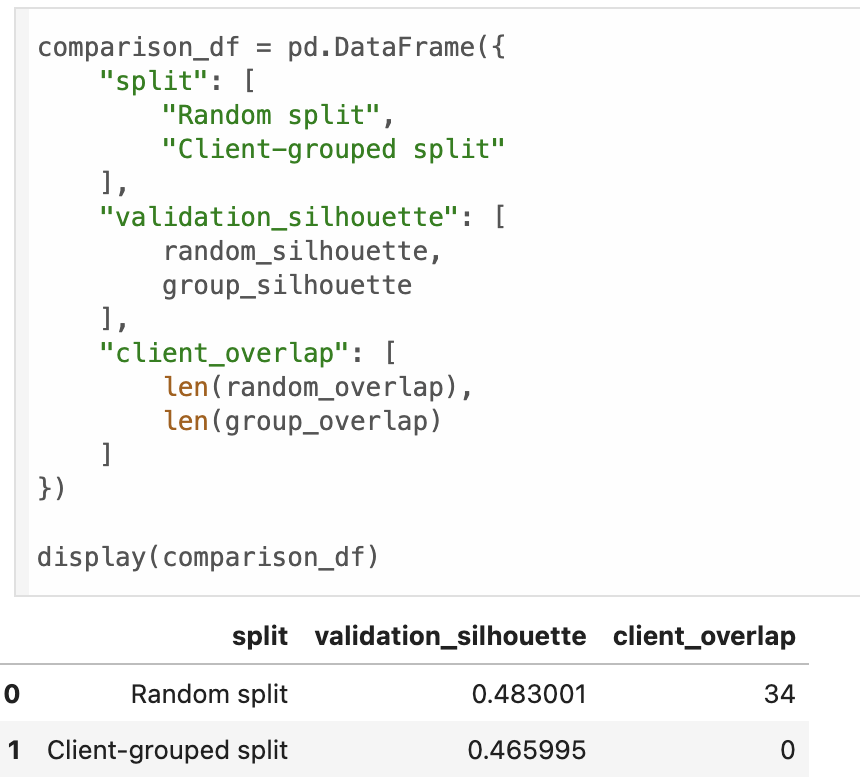

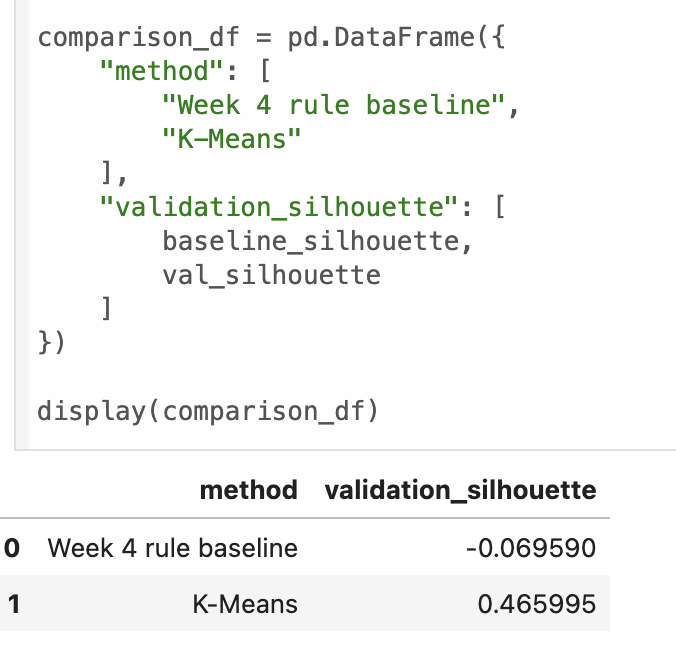

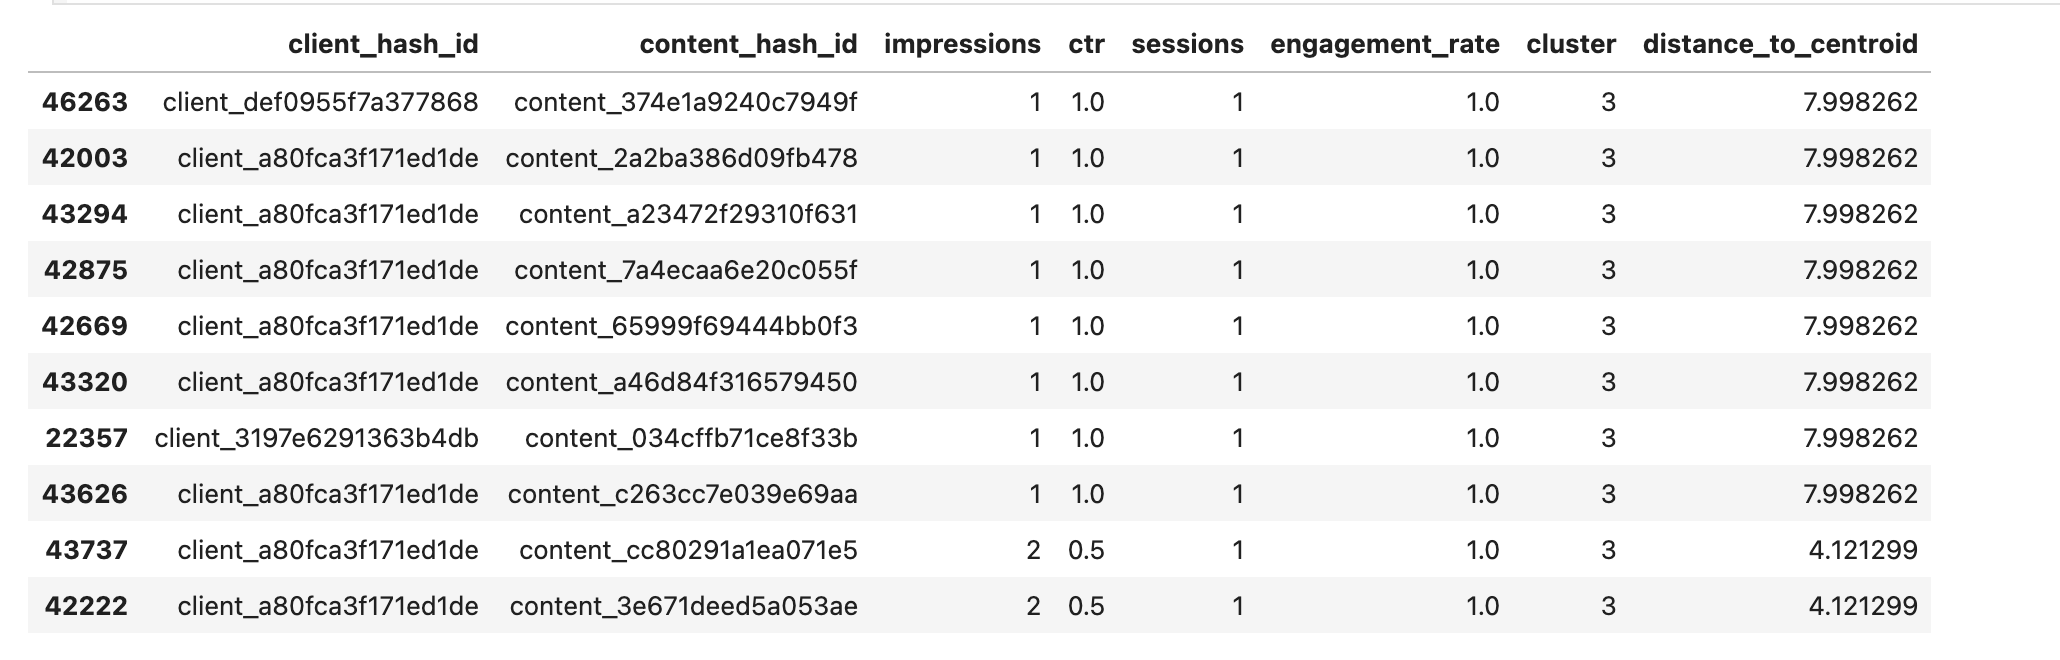

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
